# Terrain and drainage feature inspection

Elevation, slope and drainage context complement rainfall: rainfall provides a trigger, while terrain describes pathways and low ground. These layers do not themselves predict flooding.

Copernicus DEM 2024_1 is a **surface** model including buildings/vegetation. Slope is calculated at 30m in a metre-based projection before alignment. MERIT `hnd` is retained as **hydrologically adjusted elevation**; it is not assumed to be a relative height-above-channel feature. `upa` measures upstream area in km², not discharge or rainfall.

The aligned grid remains 10m, but source detail is nominally 30m or approximately 90m. The 2024_1 processed DEM edition is used for feature engineering; its availability as of the 2022 scene is not established. MERIT has known coastal/delta limitations, important in this lagoon-heavy ROI.

The local table aggregates nominal 100m cells (means, maxima, valid fractions), keeps partial edge dimensions, and leaves missing means blank. It has no labels. Future validation must separate spatial blocks/events rather than randomly splitting adjacent cells.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))


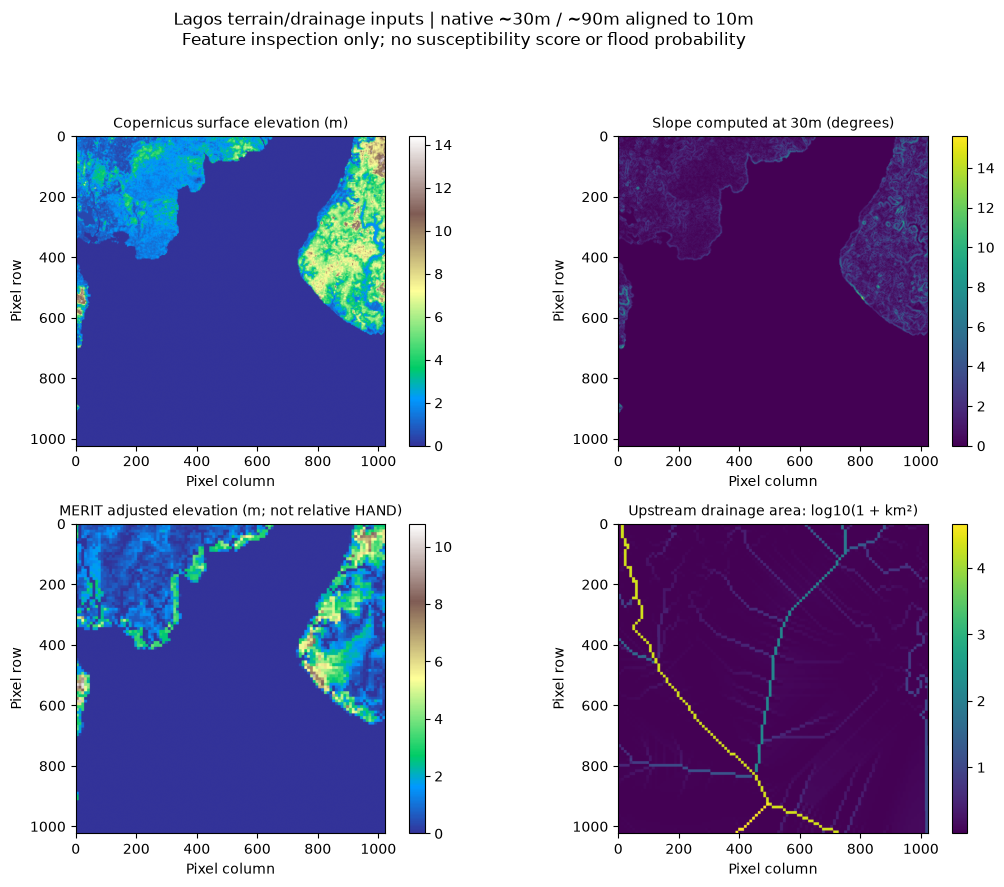

{
  "surface_elevation_m": {
    "valid_pixels": 1048576,
    "missing_pixels": 0,
    "min": 0.0,
    "median": 0.0,
    "max": 14.405298233032227
  },
  "slope_degrees": {
    "valid_pixels": 1048576,
    "missing_pixels": 0,
    "min": 0.0,
    "median": 0.0,
    "max": 15.607195854187012
  },
  "hydro_adjusted_elevation_m": {
    "valid_pixels": 1048576,
    "missing_pixels": 0,
    "min": 0.0,
    "median": 0.0,
    "max": 10.800000190734863
  },
  "upstream_area_km2": {
    "valid_pixels": 1048576,
    "missing_pixels": 0,
    "min": 0.008492391556501389,
    "median": 0.04246412217617035,
    "max": 46343.32421875
  }
}


In [2]:
import csv
import json
import shutil
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from floodrisk.acquire.terrain import BANDS,summarize
from floodrisk.deploy.tiled import file_hash

source=PROJECT / "data/terrain/lagos_first"
out=PROJECT / "reports/lagos_2022/terrain"
out.mkdir(exist_ok=True)
for name in ["terrain.json","cell_schema.json"]:shutil.copy2(source/name,out/name)
report=json.loads((out/"terrain.json").read_text())
assert file_hash(source/"terrain_features.tif")==report["sha256"]
with rasterio.open(source/"terrain_features.tif") as src:
    bands=src.read(masked=True)
    assert list(src.descriptions)==BANDS
    terrain_grid=src.crs,src.transform,src.shape
with rasterio.open(PROJECT/"data/scenes/lagos_2022/sentinel1_vv_vh_db.tif") as src:
    assert terrain_grid==(src.crs,src.transform,src.shape)
assert summarize(bands.filled(-9999))==report["statistics"]
with (source/"terrain_cells_100m.csv").open() as f:
    reader=csv.DictReader(f)
    sample=[next(reader) for _ in range(10)]
    remaining=list(reader)
    assert len(sample)+len(remaining)==10609
    assert sum(int(r["pixels"]) for r in [*sample,*remaining])==1024*1024
with (out/"cell_sample.csv").open("w") as f:
    writer=csv.DictWriter(f,fieldnames=list(sample[0]));writer.writeheader();writer.writerows(sample)
fig,axes=plt.subplots(2,2,figsize=(11,9))
titles=["Copernicus surface elevation (m)","Slope computed at 30m (degrees)","MERIT adjusted elevation (m; not relative HAND)","Upstream drainage area: log10(1 + km²)"]
for i,(ax,title) in enumerate(zip(axes.flat,titles)):
    data=bands[i] if i!=3 else np.ma.log10(1+bands[i])
    image=ax.imshow(data,cmap="terrain" if i in [0,2] else "viridis")
    ax.set_title(title,fontsize=10);ax.set_xlabel("Pixel column");ax.set_ylabel("Pixel row")
    fig.colorbar(image,ax=ax,fraction=0.046)
fig.suptitle("Lagos terrain/drainage inputs | native ~30m / ~90m aligned to 10m\nFeature inspection only; no susceptibility score or flood probability")
fig.tight_layout(rect=[0,0,1,0.94]);fig.savefig(out/"terrain_features.png",dpi=150,bbox_inches="tight")
plt.show();plt.close(fig)
print(json.dumps(report["statistics"],indent=2))
